# 기업 재무 데이터와 경제지표 연결

- 입력: `data/company_financials.csv`, `data/macro_data.csv`
- 출력: `data/company_macro_panel.csv`
- 분석 단위: 기업-회계연도
- 기간 기준: 기업별 `period_start`~`period_end`
- 실행 기준: 저장된 CSV만 사용하며 SEC·FRED API를 다시 호출하지 않음

In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def find_project_root():
    current_path = Path.cwd().resolve()
    candidate_paths = [current_path, current_path.parent]

    for candidate_path in candidate_paths:
        data_dir = candidate_path / "data"
        src_dir = candidate_path / "src"

        if data_dir.is_dir() and src_dir.is_dir():
            return candidate_path

    raise FileNotFoundError(
        "프로젝트 루트를 찾지 못했습니다. "
        "프로젝트 루트 또는 notebooks 폴더에서 실행하세요."
    )


PROJECT_ROOT = find_project_root()
COMPANY_CSV_PATH = (
    PROJECT_ROOT
    / "data"
    / "company_financials.csv"
)
MACRO_CSV_PATH = (
    PROJECT_ROOT
    / "data"
    / "macro_data.csv"
)
PANEL_CSV_PATH = (
    PROJECT_ROOT
    / "data"
    / "company_macro_panel.csv"
)

EXPECTED_TICKERS = [
    "AAPL",
    "MSFT",
    "JPM",
    "TSLA",
    "WMT",
]
EXPECTED_COMPANY_SHAPE = (25, 39)
EXPECTED_PANEL_SHAPE = (25, 56)

COMPANY_REQUIRED_COLUMNS = [
    "company_name",
    "ticker",
    "cik",
    "sector",
    "fiscal_year",
    "period_start",
    "period_end",
    "balance_sheet_date",
    "revenue_usd",
    "net_income_usd",
    "assets_usd",
    "liabilities_usd",
    "operating_cash_flow_usd",
    "source",
]
COMPANY_DATE_COLUMNS = [
    "period_start",
    "period_end",
    "balance_sheet_date",
    "revenue_filed",
    "net_income_filed",
    "assets_filed",
    "liabilities_filed",
    "operating_cash_flow_filed",
]

MONTHLY_SERIES_IDS = [
    "UNRATE",
    "FEDFUNDS",
    "CPIAUCSL",
]
DAILY_SERIES_IDS = [
    "DGS10",
    "T10Y2Y",
]
MACRO_SERIES_COLUMNS = [
    *MONTHLY_SERIES_IDS,
    *DAILY_SERIES_IDS,
]
MACRO_REQUIRED_COLUMNS = [
    "date",
    *MACRO_SERIES_COLUMNS,
]

MACRO_FEATURE_COLUMNS = [
    "fiscal_year_end_month",
    "fiscal_year_spans_two_calendar_years",
    "macro_window_start_month",
    "macro_window_end_month",
    "macro_expected_month_count",
    "macro_observed_month_count",
    "macro_missing_value_count",
    "macro_coverage_ratio",
    "macro_coverage_status",
    "unrate_mean_pct",
    "fedfunds_mean_pct",
    "cpi_start_index",
    "cpi_end_index",
    "cpi_change_pct",
    "dgs10_mean_pct",
    "t10y2y_mean_pct",
    "macro_source",
]

MACRO_VALUE_FEATURE_COLUMNS = [
    "unrate_mean_pct",
    "fedfunds_mean_pct",
    "cpi_start_index",
    "cpi_end_index",
    "cpi_change_pct",
    "dgs10_mean_pct",
    "t10y2y_mean_pct",
]

print("project_root:", PROJECT_ROOT)
print("company_csv_path:", COMPANY_CSV_PATH)
print("macro_csv_path:", MACRO_CSV_PATH)
print("panel_csv_path:", PANEL_CSV_PATH)

project_root: /Users/im-youngchan/Desktop/US Financial
company_csv_path: /Users/im-youngchan/Desktop/US Financial/data/company_financials.csv
macro_csv_path: /Users/im-youngchan/Desktop/US Financial/data/macro_data.csv
panel_csv_path: /Users/im-youngchan/Desktop/US Financial/data/company_macro_panel.csv


In [14]:
if not COMPANY_CSV_PATH.exists():
    raise FileNotFoundError(
        f"기업 재무 CSV가 없습니다: {COMPANY_CSV_PATH}"
    )

if not MACRO_CSV_PATH.exists():
    raise FileNotFoundError(
        f"경제지표 CSV가 없습니다: {MACRO_CSV_PATH}"
    )

company_df = pd.read_csv(
    COMPANY_CSV_PATH,
    dtype={"cik": "string"},
)
macro_df = pd.read_csv(MACRO_CSV_PATH)

missing_company_columns = sorted(
    set(COMPANY_REQUIRED_COLUMNS) - set(company_df.columns)
)
if missing_company_columns:
    raise KeyError(
        "기업 재무 CSV에 필요한 column이 없습니다: "
        f"{missing_company_columns}"
    )

if list(macro_df.columns) != MACRO_REQUIRED_COLUMNS:
    raise ValueError(
        "경제지표 CSV column 순서가 다릅니다: "
        f"{list(macro_df.columns)}"
    )

for date_column in COMPANY_DATE_COLUMNS:
    if date_column in company_df.columns:
        company_df[date_column] = pd.to_datetime(
            company_df[date_column],
            errors="coerce",
        )

company_df["fiscal_year"] = pd.to_numeric(
    company_df["fiscal_year"],
    errors="coerce",
)
if company_df["fiscal_year"].isna().any():
    raise ValueError("fiscal_year에 숫자로 변환되지 않은 값이 있습니다.")
company_df["fiscal_year"] = company_df["fiscal_year"].astype(int)

company_df["ticker"] = (
    company_df["ticker"]
    .astype("string")
    .str.strip()
    .str.upper()
)
company_df["cik"] = (
    company_df["cik"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(10)
)

macro_df["date"] = pd.to_datetime(
    macro_df["date"],
    errors="coerce",
)
for series_id in MACRO_SERIES_COLUMNS:
    macro_df[series_id] = pd.to_numeric(
        macro_df[series_id],
        errors="coerce",
    )

if company_df.shape != EXPECTED_COMPANY_SHAPE:
    raise ValueError(
        "기업 재무 CSV shape가 다릅니다: "
        f"{company_df.shape}"
    )

if set(company_df["ticker"].dropna()) != set(EXPECTED_TICKERS):
    raise ValueError(
        "기업 재무 CSV의 ticker 구성이 다릅니다: "
        f"{sorted(company_df['ticker'].dropna().unique())}"
    )

company_duplicate_count = company_df.duplicated(
    subset=["ticker", "fiscal_year"]
).sum()
if company_duplicate_count != 0:
    raise ValueError(
        "ticker-fiscal_year 중복이 있습니다: "
        f"{company_duplicate_count}"
    )

company_key_date_missing_count = company_df[
    ["period_start", "period_end", "balance_sheet_date"]
].isna().sum().sum()
if company_key_date_missing_count != 0:
    raise ValueError(
        "기업 재무 핵심 기간 날짜에 결측치가 있습니다: "
        f"{company_key_date_missing_count}"
    )

if not company_df["cik"].str.fullmatch(r"\d{10}").all():
    raise ValueError("cik가 10자리 숫자 문자열이 아닙니다.")

if macro_df["date"].isna().any():
    raise ValueError("경제지표 CSV에 변환되지 않은 날짜가 있습니다.")

if macro_df["date"].duplicated().any():
    raise ValueError("경제지표 CSV에 중복 날짜가 있습니다.")

macro_df = macro_df.sort_values("date").reset_index(drop=True)

print("company_shape:", company_df.shape)
print("company_tickers:", sorted(company_df["ticker"].unique()))
print(
    "company_fiscal_year_range:",
    company_df["fiscal_year"].min(),
    company_df["fiscal_year"].max(),
)
print("macro_shape:", macro_df.shape)
print("macro_first_date:", macro_df["date"].min().date())
print("macro_last_date:", macro_df["date"].max().date())
print("macro_missing_summary:")
print(macro_df[MACRO_SERIES_COLUMNS].isna().sum())

company_shape: (25, 39)
company_tickers: ['AAPL', 'JPM', 'MSFT', 'TSLA', 'WMT']
company_fiscal_year_range: 2021 2025
macro_shape: (1585, 6)
macro_first_date: 2019-01-01
macro_last_date: 2024-12-31
macro_missing_summary:
UNRATE      1513
FEDFUNDS    1513
CPIAUCSL    1513
DGS10         84
T10Y2Y        84
dtype: int64


In [15]:
def build_monthly_macro(macro_data):
    working_df = macro_data.copy()
    working_df["month"] = working_df["date"].dt.to_period("M")

    monthly_parts = []

    for series_id in MONTHLY_SERIES_IDS:
        monthly_observations = working_df.loc[
            working_df[series_id].notna(),
            ["date", "month", series_id],
        ].copy()

        duplicate_month_count = (
            monthly_observations
            .groupby("month")
            .size()
            .gt(1)
            .sum()
        )
        if duplicate_month_count != 0:
            raise ValueError(
                f"{series_id}에 한 달 두 개 이상의 값이 있습니다: "
                f"{duplicate_month_count}"
            )

        monthly_series = (
            monthly_observations
            .sort_values("date")
            .groupby("month")[series_id]
            .last()
        )
        monthly_parts.append(monthly_series)

    for series_id in DAILY_SERIES_IDS:
        daily_observations = working_df.loc[
            working_df[series_id].notna(),
            ["month", series_id],
        ].copy()

        monthly_series = (
            daily_observations
            .groupby("month")[series_id]
            .mean()
        )
        monthly_parts.append(monthly_series)

    monthly_macro_df = (
        pd.concat(monthly_parts, axis=1)
        .sort_index()
        .reset_index()
    )

    monthly_macro_df["month_start"] = (
        monthly_macro_df["month"]
        .dt.to_timestamp(how="start")
    )
    monthly_macro_df["month_end"] = (
        monthly_macro_df["month"]
        .dt.to_timestamp(how="end")
        .dt.normalize()
    )

    monthly_macro_df = monthly_macro_df[
        [
            "month",
            "month_start",
            "month_end",
            *MACRO_SERIES_COLUMNS,
        ]
    ]

    return monthly_macro_df


monthly_macro_df = build_monthly_macro(macro_df)

expected_months = pd.period_range(
    start=monthly_macro_df["month"].min(),
    end=monthly_macro_df["month"].max(),
    freq="M",
)

if list(monthly_macro_df["month"]) != list(expected_months):
    raise ValueError("월별 macro 표의 calendar month가 연속적이지 않습니다.")

if monthly_macro_df["month"].duplicated().any():
    raise ValueError("월별 macro 표에 중복 month가 있습니다.")

print("monthly_macro_shape:", monthly_macro_df.shape)
print("monthly_macro_first_month:", monthly_macro_df["month"].min())
print("monthly_macro_last_month:", monthly_macro_df["month"].min())
print("monthly_macro_missing_summary:")
print(monthly_macro_df[MACRO_SERIES_COLUMNS].isna().sum())

display(monthly_macro_df.head())

monthly_macro_shape: (72, 8)
monthly_macro_first_month: 2019-01
monthly_macro_last_month: 2019-01
monthly_macro_missing_summary:
UNRATE      0
FEDFUNDS    0
CPIAUCSL    0
DGS10       0
T10Y2Y      0
dtype: int64


,month,month_start,month_end,UNRATE,FEDFUNDS,CPIAUCSL,DGS10,T10Y2Y
0,2019-01,2019-01-01,2019-01-31,4.0,2.40,252.561,2.713810,0.170476
1,2019-02,2019-02-01,2019-02-28,3.8,2.40,253.319,2.676316,0.172105
2,2019-03,2019-03-01,2019-03-31,3.8,2.41,254.277,2.570952,0.161429
3,2019-04,2019-04-01,2019-04-30,3.7,2.42,255.233,2.532381,0.187619
4,2019-05,2019-05-01,2019-05-31,3.6,2.39,255.296,2.395000,0.188636


In [16]:
def expected_months_for_period(period_start, period_end):
    if pd.isna(period_start) or pd.isna(period_end):
        raise ValueError("회계기간 시작일 또는 종료일이 없습니다.")

    if period_start > period_end:
        raise ValueError("period_start가 period_end보다 늦습니다.")

    candidate_months = pd.period_range(
        start=period_start.to_period("M"),
        end=period_end.to_period("M"),
        freq="M",
    )
    candidate_month_starts = candidate_months.to_timestamp(
        how="start"
    )

    inside_period_mask = (
        (candidate_month_starts >= period_start.normalize())
        & (candidate_month_starts <= period_end.normalize())
    )
    expected_months = candidate_months[inside_period_mask]

    if len(expected_months) == 0:
        raise ValueError("회계기간 안에 선택된 calendar month가 없습니다.")

    return expected_months


sample_row = (
    company_df
    .loc[
        (company_df["ticker"] == "AAPL")
        & (company_df["fiscal_year"] == 2024)
    ]
    .iloc[0]
)

sample_expected_months = expected_months_for_period(
    period_start=sample_row["period_start"],
    period_end=sample_row["period_end"],
)

print("sample_ticker:", sample_row["ticker"])
print("sample_fiscal_year:", sample_row["fiscal_year"])
print("sample_period_start:", sample_row["period_start"].date())
print("sample_period_end:", sample_row["period_end"].date())
print("sample_expected_month_count:", len(sample_expected_months))
print("sample_first_month:", sample_expected_months[0])
print("sample_last_month:", sample_expected_months[-1])

sample_ticker: AAPL
sample_fiscal_year: 2024
sample_period_start: 2023-10-01
sample_period_end: 2024-09-28
sample_expected_month_count: 12
sample_first_month: 2023-10
sample_last_month: 2024-09


In [17]:
def mean_or_nan(dataframe, column_name):
    valid_values = dataframe[column_name].dropna()

    if valid_values.empty:
        return np.nan

    return valid_values.mean()


def summarize_macro_window(company_row, monthly_macro_data):
    period_start = company_row["period_start"]
    period_end = company_row["period_end"]

    expected_months = expected_months_for_period(
        period_start=period_start,
        period_end=period_end,
    )

    window_df = (
        monthly_macro_data
        .loc[
            monthly_macro_data["month"].isin(expected_months)
        ]
        .sort_values("month")
        .reset_index(drop=True)
    )

    expected_month_count = len(expected_months)
    observed_month_count = len(window_df)
    missing_value_count = int(
        window_df[MACRO_SERIES_COLUMNS]
        .isna()
        .sum()
        .sum()
    )
    coverage_ratio = (
        observed_month_count / expected_month_count
    )

    if observed_month_count == 0:
        coverage_status = "missing"
    elif (
        observed_month_count == expected_month_count
        and missing_value_count == 0
    ):
        coverage_status = "complete"
    else:
        coverage_status = "partial"

    cpi_values = window_df["CPIAUCSL"].dropna()

    if cpi_values.empty:
        cpi_start_index = np.nan
        cpi_end_index = np.nan
        cpi_change_pct = np.nan
    else:
        cpi_start_index = cpi_values.iloc[0]
        cpi_end_index = cpi_values.iloc[-1]

        if cpi_start_index == 0:
            cpi_change_pct = np.nan
        else:
            cpi_change_pct = (
                (cpi_end_index / cpi_start_index) - 1
            ) * 100

    return {
        "fiscal_year_end_month": int(period_end.month),
        "fiscal_year_spans_two_calendar_years": (
            period_start.year != period_end.year
        ),
        "macro_window_start_month": (
            expected_months[0].to_timestamp(how="start")
        ),
        "macro_window_end_month": (
            expected_months[-1].to_timestamp(how="start")
        ),
        "macro_expected_month_count": expected_month_count,
        "macro_observed_month_count": observed_month_count,
        "macro_missing_value_count": missing_value_count,
        "macro_coverage_ratio": coverage_ratio,
        "macro_coverage_status": coverage_status,
        "unrate_mean_pct": mean_or_nan(window_df, "UNRATE"),
        "fedfunds_mean_pct": mean_or_nan(
            window_df,
            "FEDFUNDS",
        ),
        "cpi_start_index": cpi_start_index,
        "cpi_end_index": cpi_end_index,
        "cpi_change_pct": cpi_change_pct,
        "dgs10_mean_pct": mean_or_nan(window_df, "DGS10"),
        "t10y2y_mean_pct": mean_or_nan(
            window_df,
            "T10Y2Y",
        ),
        "macro_source": "FRED",
    }

In [18]:
macro_summary_records = []

for _, company_row in company_df.iterrows():
    summary_record = {
        "ticker": company_row["ticker"],
        "fiscal_year": int(company_row["fiscal_year"]),
    }
    summary_record.update(
        summarize_macro_window(
            company_row=company_row,
            monthly_macro_data=monthly_macro_df,
        )
    )
    macro_summary_records.append(summary_record)

macro_summary_df = pd.DataFrame(macro_summary_records)
macro_summary_df = macro_summary_df[
    [
        "ticker",
        "fiscal_year",
        *MACRO_FEATURE_COLUMNS,
    ]
]

macro_summary_df[
    [
        "macro_coverage_ratio",
        *MACRO_VALUE_FEATURE_COLUMNS,
    ]
] = macro_summary_df[
    [
        "macro_coverage_ratio",
        *MACRO_VALUE_FEATURE_COLUMNS,
    ]
].round(4)

if macro_summary_df.duplicated(
    subset=["ticker", "fiscal_year"]
).any():
    raise ValueError("macro summary key가 중복되었습니다.")

print("macro_summary_shape:", macro_summary_df.shape)
print("macro_coverage_status_counts:")
print(
    macro_summary_df["macro_coverage_status"]
    .value_counts(dropna=False)
)

display(
    macro_summary_df.loc[
        macro_summary_df["fiscal_year"] == 2025,
        [
            "ticker",
            "fiscal_year",
            "macro_window_start_month",
            "macro_window_end_month",
            "macro_expected_month_count",
            "macro_observed_month_count",
            "macro_coverage_ratio",
            "macro_coverage_status",
        ],
    ]
)

macro_summary_shape: (25, 19)
macro_coverage_status_counts:
macro_coverage_status
complete    20
partial      3
missing      2
Name: count, dtype: int64


,ticker,fiscal_year,macro_window_start_month,macro_window_end_month,macro_expected_month_count,macro_observed_month_count,macro_coverage_ratio,macro_coverage_status
4,AAPL,2025,2024-10-01,2025-09-01,12,3,0.2500,partial
9,JPM,2025,2025-01-01,2025-12-01,12,0,0.0000,missing
14,MSFT,2025,2024-07-01,2025-06-01,12,6,0.5000,partial
19,TSLA,2025,2025-01-01,2025-12-01,12,0,0.0000,missing
24,WMT,2025,2024-02-01,2025-01-01,12,11,0.9167,partial


In [19]:
company_columns = list(company_df.columns)

panel_df = company_df.merge(
    macro_summary_df,
    on=["ticker", "fiscal_year"],
    how="left",
    validate="one_to_one",
)
panel_df = panel_df[
    [
        *company_columns,
        *MACRO_FEATURE_COLUMNS,
    ]
]

sort_order_map = {
    ticker: order
    for order, ticker in enumerate(EXPECTED_TICKERS)
}
panel_df["_ticker_order"] = panel_df["ticker"].map(
    sort_order_map
)
panel_df = (
    panel_df
    .sort_values(["_ticker_order", "fiscal_year"])
    .drop(columns="_ticker_order")
    .reset_index(drop=True)
)

if panel_df.shape != EXPECTED_PANEL_SHAPE:
    raise ValueError(
        "최종 panel shape가 다릅니다: "
        f"{panel_df.shape}"
    )

if panel_df.duplicated(
    subset=["ticker", "fiscal_year"]
).any():
    raise ValueError("최종 panel key가 중복되었습니다.")

if not panel_df["macro_coverage_ratio"].between(0, 1).all():
    raise ValueError("macro_coverage_ratio가 0~1 범위를 벗어났습니다.")

allowed_coverage_statuses = {
    "complete",
    "partial",
    "missing",
}
if not set(panel_df["macro_coverage_status"]).issubset(
    allowed_coverage_statuses
):
    raise ValueError("알 수 없는 macro coverage 상태가 있습니다.")

complete_rows = panel_df.loc[
    panel_df["macro_coverage_status"] == "complete"
]
if not complete_rows["macro_coverage_ratio"].eq(1).all():
    raise ValueError("complete row의 coverage ratio가 1이 아닙니다.")

if not complete_rows["macro_missing_value_count"].eq(0).all():
    raise ValueError("complete row에 macro 결측값이 있습니다.")

missing_rows = panel_df.loc[
    panel_df["macro_coverage_status"] == "missing"
]
if not missing_rows[MACRO_VALUE_FEATURE_COLUMNS].isna().all().all():
    raise ValueError("missing row에 macro 요약값이 들어 있습니다.")

original_company_check = (
    company_df
    .sort_values(["ticker", "fiscal_year"])
    .reset_index(drop=True)
)
merged_company_check = (
    panel_df[company_columns]
    .sort_values(["ticker", "fiscal_year"])
    .reset_index(drop=True)
)

pd.testing.assert_frame_equal(
    original_company_check,
    merged_company_check,
    check_dtype=False,
)

coverage_status_counts = (
    panel_df["macro_coverage_status"]
    .value_counts()
    .to_dict()
)

if monthly_macro_df["month"].max() == pd.Period("2024-12"):
    expected_status_counts = {
        "complete": 20,
        "partial": 3,
        "missing": 2,
    }

    if coverage_status_counts != expected_status_counts:
        raise ValueError(
            "현재 고정 입력에서 coverage 상태 개수가 다릅니다: "
            f"{coverage_status_counts}"
        )

print("panel_shape:", panel_df.shape)
print("panel_column_count:", len(panel_df.columns))
print("panel_duplicate_key_count:", panel_df.duplicated(
    subset=["ticker", "fiscal_year"]
).sum())
print("company_columns_preserved:", True)
print("coverage_status_counts:", coverage_status_counts)

panel_shape: (25, 56)
panel_column_count: 56
panel_duplicate_key_count: 0
company_columns_preserved: True
coverage_status_counts: {'complete': 20, 'partial': 3, 'missing': 2}


In [20]:
PANEL_DATE_COLUMNS = [
    *COMPANY_DATE_COLUMNS,
    "macro_window_start_month",
    "macro_window_end_month",
]

temporary_path = PANEL_CSV_PATH.with_suffix(".csv.tmp")

panel_df.to_csv(
    temporary_path,
    index=False,
    date_format="%Y-%m-%d",
)
temporary_path.replace(PANEL_CSV_PATH)

saved_panel_df = pd.read_csv(
    PANEL_CSV_PATH,
    dtype={"cik": "string"},
    parse_dates=PANEL_DATE_COLUMNS,
)

if saved_panel_df.shape != EXPECTED_PANEL_SHAPE:
    raise ValueError(
        "저장한 panel shape가 다릅니다: "
        f"{saved_panel_df.shape}"
    )

if list(saved_panel_df.columns) != list(panel_df.columns):
    raise ValueError("저장 전후 panel column 순서가 다릅니다.")

if saved_panel_df.duplicated(
    subset=["ticker", "fiscal_year"]
).any():
    raise ValueError("저장한 panel에 중복 key가 있습니다.")

if not saved_panel_df["cik"].str.fullmatch(r"\d{10}").all():
    raise ValueError("저장한 panel의 CIK 형식이 잘못되었습니다.")

print("saved_panel_path:", PANEL_CSV_PATH)
print("saved_panel_exists:", PANEL_CSV_PATH.exists())
print("saved_panel_shape:", saved_panel_df.shape)
print("saved_panel_columns:", list(saved_panel_df.columns))
print("saved_coverage_status_counts:")
print(
    saved_panel_df["macro_coverage_status"]
    .value_counts(dropna=False)
)

saved_panel_path: /Users/im-youngchan/Desktop/US Financial/data/company_macro_panel.csv
saved_panel_exists: True
saved_panel_shape: (25, 56)
saved_panel_columns: ['company_name', 'ticker', 'cik', 'sector', 'fiscal_year', 'period_start', 'period_end', 'balance_sheet_date', 'revenue_usd', 'net_income_usd', 'assets_usd', 'liabilities_usd', 'operating_cash_flow_usd', 'form', 'unit', 'revenue_concept', 'net_income_concept', 'assets_concept', 'liabilities_concept', 'operating_cash_flow_concept', 'revenue_duration_days', 'net_income_duration_days', 'operating_cash_flow_duration_days', 'revenue_filed', 'net_income_filed', 'assets_filed', 'liabilities_filed', 'operating_cash_flow_filed', 'revenue_accn', 'net_income_accn', 'assets_accn', 'liabilities_accn', 'operating_cash_flow_accn', 'duration_dates_match', 'instant_dates_match', 'period_end_matches_balance_sheet_date', 'metric_coverage_count', 'missing_metrics', 'source', 'fiscal_year_end_month', 'fiscal_year_spans_two_calendar_years', 'macro_

In [21]:
SELECTED_TICKER = "AAPL"

analysis_df = (
    panel_df
    .loc[panel_df["ticker"] == SELECTED_TICKER]
    .sort_values("fiscal_year")
    .copy()
)
analysis_df["revenue_usd_billions"] = (
    analysis_df["revenue_usd"] / 1_000_000_000
)
analysis_df["net_income_usd_billions"] = (
    analysis_df["net_income_usd"] / 1_000_000_000
)

analysis_columns = [
    "ticker",
    "fiscal_year",
    "period_start",
    "period_end",
    "revenue_usd_billions",
    "net_income_usd_billions",
    "unrate_mean_pct",
    "fedfunds_mean_pct",
    "cpi_change_pct",
    "dgs10_mean_pct",
    "t10y2y_mean_pct",
    "macro_coverage_status",
]

display(analysis_df[analysis_columns])

,ticker,fiscal_year,period_start,period_end,revenue_usd_billions,net_income_usd_billions,unrate_mean_pct,fedfunds_mean_pct,cpi_change_pct,dgs10_mean_pct,t10y2y_mean_pct,macro_coverage_status
0,AAPL,2021,2020-09-27,2021-09-25,365.817,94.680,6.0000,0.0825,5.2209,1.2744,1.1041,complete
1,AAPL,2022,2021-09-26,2022-09-24,394.328,99.803,3.8000,0.7900,7.1593,2.3779,0.3611,complete
2,AAPL,2023,2022-09-25,2023-09-30,383.285,96.995,3.5667,4.6050,3.1103,3.8050,-0.6742,complete
3,AAPL,2024,2023-10-01,2024-09-28,391.035,93.736,3.9417,5.3133,2.2867,4.2471,-0.2873,complete
4,AAPL,2025,2024-09-29,2025-09-27,416.161,112.010,4.1333,4.6500,0.6251,4.2809,0.1291,partial


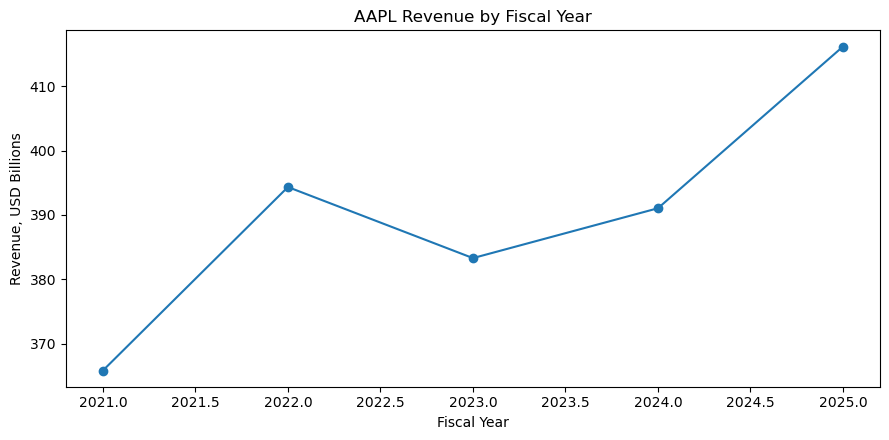

In [22]:
plt.figure(figsize=(9, 4.5))
plt.plot(
    analysis_df["fiscal_year"],
    analysis_df["revenue_usd_billions"],
    marker="o",
)
plt.title(f"{SELECTED_TICKER} Revenue by Fiscal Year")
plt.xlabel("Fiscal Year")
plt.ylabel("Revenue, USD Billions")
plt.tight_layout()
plt.show()

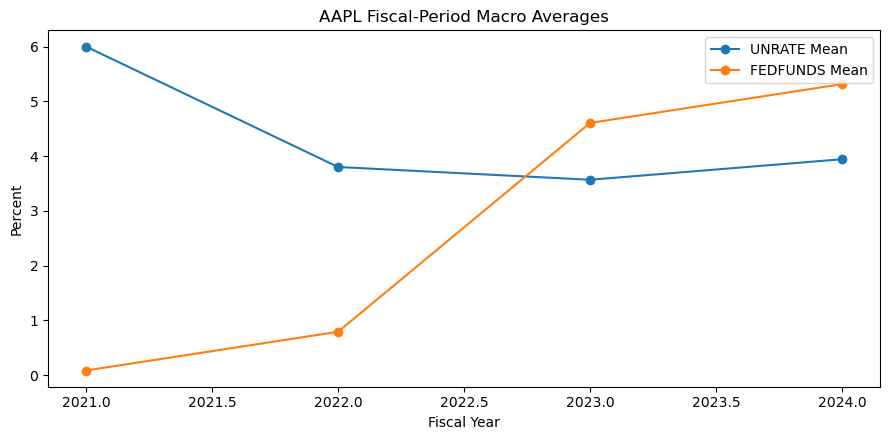

In [23]:
complete_analysis_df = analysis_df.loc[
    analysis_df["macro_coverage_status"] == "complete"
].copy()

plt.figure(figsize=(9, 4.5))
plt.plot(
    complete_analysis_df["fiscal_year"],
    complete_analysis_df["unrate_mean_pct"],
    marker="o",
    label="UNRATE Mean",
)
plt.plot(
    complete_analysis_df["fiscal_year"],
    complete_analysis_df["fedfunds_mean_pct"],
    marker="o",
    label="FEDFUNDS Mean",
)
plt.title(
    f"{SELECTED_TICKER} Fiscal-Period Macro Averages"
)
plt.xlabel("Fiscal Year")
plt.ylabel("Percent")
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
fiscal_year_2024_periods = (
    panel_df
    .loc[
        panel_df["fiscal_year"] == 2024,
        [
            "ticker",
            "fiscal_year",
            "period_start",
            "period_end",
            "fiscal_year_end_month",
            "fiscal_year_spans_two_calendar_years",
            "macro_window_start_month",
            "macro_window_end_month",
            "macro_expected_month_count",
            "macro_coverage_status",
        ],
    ]
    .sort_values("ticker")
)

display(fiscal_year_2024_periods)

,ticker,fiscal_year,period_start,period_end,fiscal_year_end_month,fiscal_year_spans_two_calendar_years,macro_window_start_month,macro_window_end_month,macro_expected_month_count,macro_coverage_status
3,AAPL,2024,2023-10-01,2024-09-28,9,True,2023-10-01,2024-09-01,12,complete
13,JPM,2024,2024-01-01,2024-12-31,12,False,2024-01-01,2024-12-01,12,complete
8,MSFT,2024,2023-07-01,2024-06-30,6,True,2023-07-01,2024-06-01,12,complete
18,TSLA,2024,2024-01-01,2024-12-31,12,False,2024-01-01,2024-12-01,12,complete
23,WMT,2024,2023-02-01,2024-01-31,1,True,2023-02-01,2024-01-01,12,complete
